In [1]:
base ="klue/bert-base"
# base = 'BM-K/KoSimCSE-bert'

In [2]:
from utils.preprocess import *
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(base)
temp = load_data_and_tokenize(tok, "./Text Classification Dataset/train.csv")

In [3]:
ds_train, ds_test = balanced_train_test_split(temp,ratio=0.3)
ds_test, ds_validation = balanced_train_test_split(ds_test,ratio=0.5)

In [5]:
from transformers import AutoModelForSequenceClassification

class HFSeqClsBinaryWrapper(nn.Module):
    """
    AutoModelForSequenceClassification을 1-logit + BCEWithLogitsLoss 스타일로 쓰기 위한 래퍼
    """
    def __init__(self, base_model_name, freeze_bert=True):
        super().__init__()
        self.model = AutoModelForSequenceClassification.from_pretrained(
            base_model_name,
            num_labels=1,   # 1개 로짓
        )
        if freeze_bert:
            for p in self.model.base_model.parameters():
                p.requires_grad = False

    def forward(self, input_ids, attention_mask):
        out = self.model(input_ids=input_ids, attention_mask=attention_mask)
        logits = out.logits.squeeze(-1)   # (N, 1) -> (N,)
        return logits


In [7]:
import torch.nn as nn
from utils.models import *
from transformers import DataCollatorWithPadding

device = "cuda"
model = HFSeqClsBinaryWrapper(base).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=None)
optimizer = get_optimizer(model)

num_epochs = 1 # 1, 5 에폭
collator = DataCollatorWithPadding(tokenizer=tok)
train_model(model, ds_train, ds_test, optimizer, collator, criterion, num_epochs=num_epochs)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at klue/bert-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


epoch 1 end
train_loss: 0.20361058316133207
val_loss: 0.17761355638504028


loss:0.17954199016094208
accuracy:0.9485490841736983
f1_score:0.5567375886524822


<Axes: xlabel='generated', ylabel='pred'>

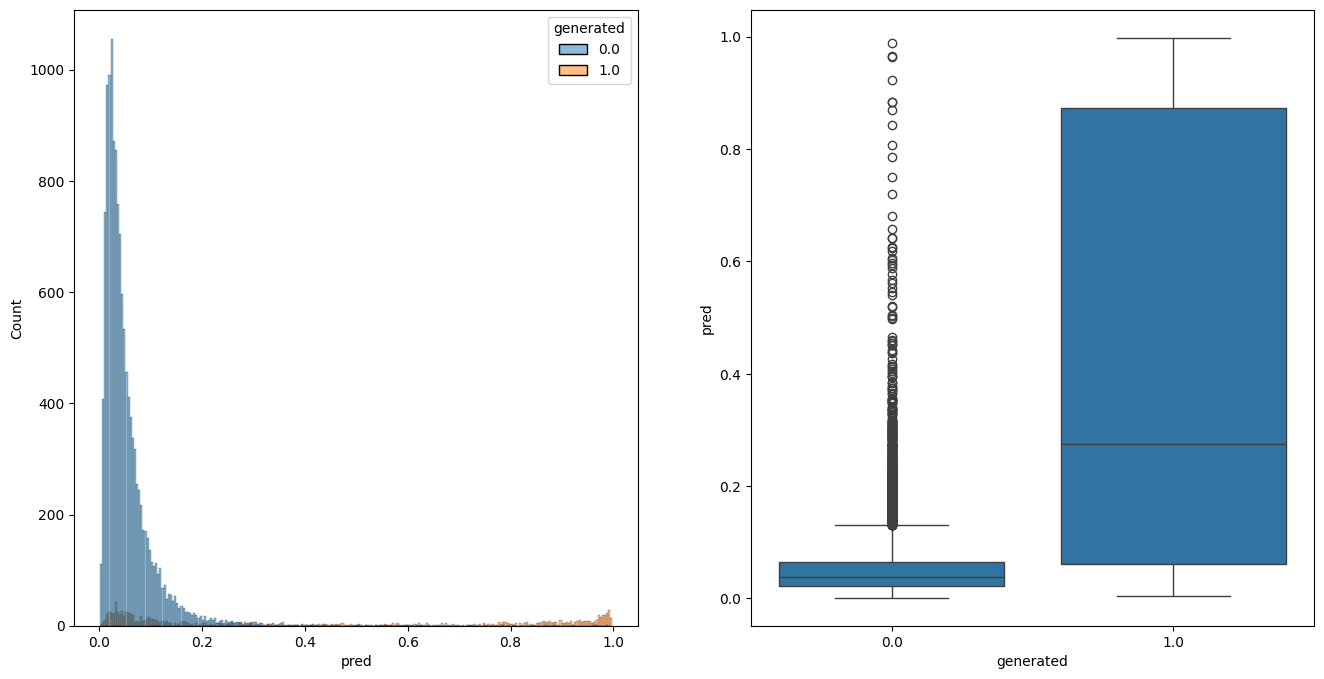

In [8]:
#1에폭일때 결과
preds, targets = get_preds(model, ds_validation, collator)
print(f'loss:{evaluate(model, ds_validation, criterion, collator)}')
print(f'accuracy:{get_metric(preds, targets, 0.6, 'accuracy')}')
print(f'f1_score:{get_metric(preds, targets, 0.6, 'f1_score')}')

import pandas as pd
ret = pd.DataFrame({
    'pred': preds,
    'generated': targets,
})
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(16,8))
sns.histplot(ret, x='pred', hue='generated', ax=ax[0])
sns.boxplot(ret, x='generated', y='pred', ax=ax[1])

loss:0.1700892299413681
accuracy:0.9530767647664128
f1_score:0.6157303370786517


<Axes: xlabel='generated', ylabel='pred'>

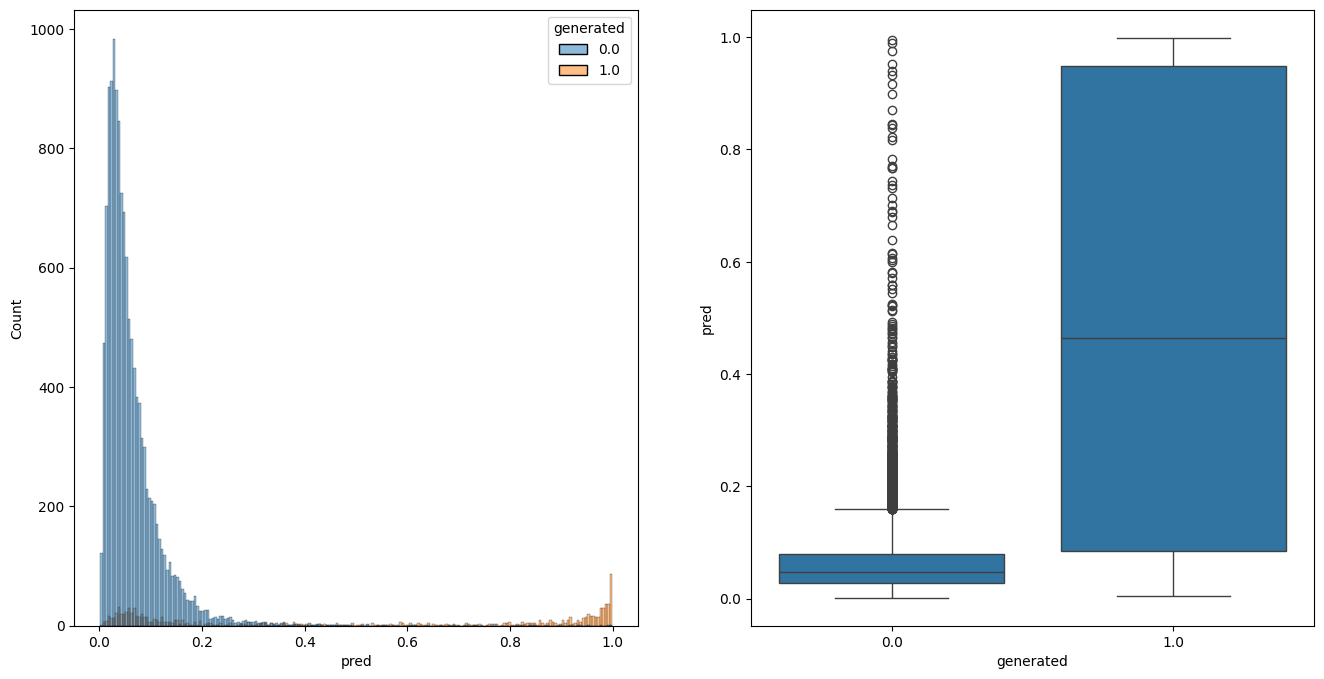

In [ ]:
#5에폭일때 결과
preds, targets = get_preds(model, ds_validation, collator)
print(f'loss:{evaluate(model, ds_validation, criterion, collator)}')
print(f'accuracy:{get_metric(preds, targets, 0.6, 'accuracy')}')
print(f'f1_score:{get_metric(preds, targets, 0.6, 'f1_score')}')

import pandas as pd
ret = pd.DataFrame({
    'pred': preds,
    'generated': targets,
})
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2,figsize=(16,8))
sns.histplot(ret, x='pred', hue='generated', ax=ax[0])
sns.boxplot(ret, x='generated', y='pred', ax=ax[1])

In [ ]:
# torch.save(model.state_dict(), 'Default_5epoch_20251205.pth')
torch.save(model.state_dict(), 'Default_1epoch_20251205.pth')